# Exercise Sheet for Interpolation and Approximation
----------------------------------------------------------

In [157]:
#load some python packages you will need
import numpy as np                 #this helps compute things
import matplotlib.pyplot as plt    #this helps plot things
import scipy

## Question 1
### a) Compute via interpolation and plot the Lagrange polynomial p(x) to $f(x) = cos(-2\pi x) + 0.4x^2$ over
### $(x_i,y_i) = [(7.2,21.04),(7.4,21.12),(7.6,22.39),(7.8,24.77]$ 


### b) Estimate the maximum absolute error bound for this Lagrange polynomial approximation over $\xi \in [x_0,x_n]$

In [158]:
x = np.arange(7,8,0.001)   #dummy range for function
y = np.cos(-2*np.pi*x) +0.4*x**2  #function f(x)


In [159]:
xi = np.array((7.2,7.4,7.6,7.8))   # points for interpolation
yi = y[np.digitize(xi,x)]

# lagrange interpolation:

#x = len(x) # x array 
# summe mit for loop 
#sum = 0 
#L = [10,12,43,54] 
#n = len(L)
#for i in range(n):
 #   print(f'{i}: {L[i]}')
  #  sum = sum + L[i]

# produkt: 
#prod = 1

#for j in range(n):
#    prod = prod * L[i]

#print(sum)
#print(prod)

# np.sum(), np.prod() versuchen zum verstehen 


In [160]:
# a 
def lagrange_interpolation(xi,yi,x_eval):
    n = len(xi)
    p_values = []
    
    for xp in x_eval:
        total = 0
        for i in range(n): 
            L_i = 1 
            for j in range(n):
                if (j != i):
                    L_i *= ((xp-xi[j])/(xi[i]-xi[j])) # += is like L_i = L_i * (...)
            total += yi[i] * L_i
        p_values.append(total)
    return np.array(p_values)

p = lagrange_interpolation(xi, yi, x)

In [161]:
# b 
from math import factorial

n = len(xi) - 1 # n=3

xx = np.linspace(xi[0], xi[-1], 10000) # nimmt das erste element und das letzte des arrays, 10000 schritte
f4 = (2*np.pi)**4 * np.cos(2*np.pi*xx) # 4. Ableitung für 4 Punkte (Formel)
max_f4 = np.max(np.abs(f4))

prod = np.ones_like(xx) 
for xj in xi: # like sum but for products -> np.prod() alternative
    prod *= (xx - xj) 
max_prod = np.max(np.abs(prod)) # formula slides

Ex = max_f4 / factorial(n + 1) * max_prod # Ex = error bound 
print(f'max |f4| = {max_f4}')
print(f'max |product| = {max_prod}')
print(f'error bound = {Ex}')

max |f4| = 1558.5454288504914
max |product| = 0.001599999993809369
error bound = 0.10390302818801693


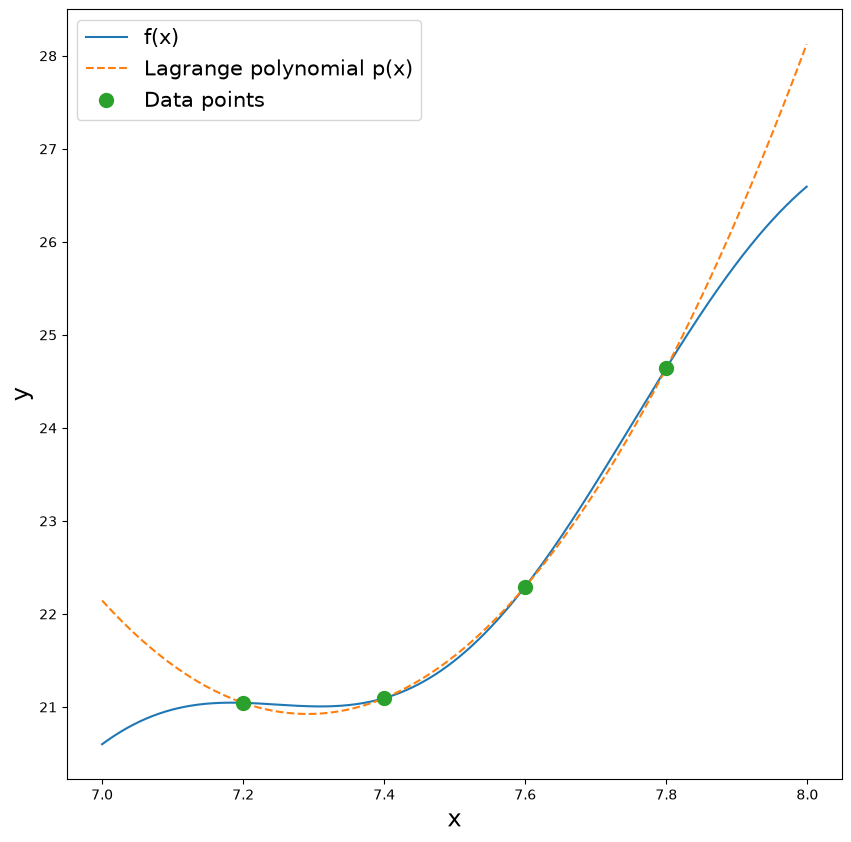

In [162]:
plt.figure(figsize=(10,10))
plt.plot(x,y,label='f(x)')  
plt.plot(x, p, '--', label='Lagrange polynomial p(x)')
plt.plot(xi,yi,'o',markersize=10, label='Data points')
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)
plt.legend(fontsize=15)
plt.show()


----------------------------------------------------------

## Question 2
### Assume linear interpolation with step size $\textbf{d}$ is used to approximate $y(x) = \pi x^7$
### What step size for linear interpolation do you need to have for an absolute error $E_{max} < 10^{-6}$?. You can assume  $x \in [0,2]$.

In [163]:
# step size damit fehler kleiner ist
# Formel: Epsilon = max in Intervall [a,b] von ( f(x)^(n+1) / (n+1)! ) * 1/2 oder 1/4 ? 
# Epsilon_max ist 10^(-6) 
# Schrittweite d = root( Epsilon_max / Epsilon )

E_max = 1e-6

def f2(x):
    return 42 * np.pi * x**5 # zweite ableitung 

xx = np.linspace(0, 2, 100000) 
max_f2 = np.max(np.abs(f2(xx)))

epsilon = max_f2 / 2 *1/4 

d = np.sqrt(E_max / epsilon) # tutorial class 

print(f'max |f| =', max_f2)
print(f'epsilon =', epsilon)
print(f'step size d=', d)
print(f'number of intervals in [0,2]:', 2 / d)

# Checking if results are correct, actual_max_error must be smaller than E_max ; I used AI for the following
d_check = 4.3e-5                                  # slightly below the computed d
x_nodes = np.arange(0, 2 + d_check, d_check)
y_nodes = np.pi * x_nodes**7

x_test = np.linspace(0, 2, 100000)
y_true = np.pi * x_test**7
y_lin = np.interp(x_test, x_nodes, y_nodes)       # built-in linear interpolation

print('actual max error =', np.max(np.abs(y_true - y_lin)))   # should be below 1e-6

max |f| = 4222.300526424682
epsilon = 527.7875658030853
step size d= 4.3528171377568164e-05
number of intervals in [0,2]: 45947.255230452465
actual max error = 9.748189313540934e-07


----------------------------------------------------------

## Question 3
### When using Taylor polynomials to approximate $y = cos(-3 \pi x) + 3x$ over the range $x = [-0.25,0.25]$, about $x= 0$;  to what order $j$ would you need to compute the interpolating polynomial in order to keep the maximum absolute error smaller than $E_{j}(x) < 10^{-6}$?

In [164]:
# E = p(x) - f(x) = .... (slides) !! slide 48 

# j = Ordnung von Taylorpolynom -y wollen wir herausfinden
# a = 0, weil about x = 0, wegen dem Ursprung 

# E = (( 3 * pi)^(j+1) / (j+1) ) * (x_max^(j + 1)) -> x_max hier 0.25 

# j = o 
# while E >= 10^-6:
    # E = Formel 
    # j += 1 
# j ist unser Grad der Taylerpolynom -> ca. 13 oder 14 Grade 

E_max = 1e-6
x_max = 0.25

j = 0
E = (3 * np.pi)**(j+1) / factorial(j+1) * x_max**(j+1)

while E >= E_max:
    E = E = (3 * np.pi)**(j+1) / factorial(j+1) * x_max**(j+1)
    j += 1
    
print(f'order of j=', j)
print(f'error bound E_j=', E)


# Checking results with AI: 
x = np.linspace(-0.25, 0.25, 1000)
f = np.cos(-3*np.pi*x) + 3*x

p = 3*x                                   # the 3x part is exact
for k in range(0, 8):                     # cos terms up to power 14
    p += (-1)**k * (3*np.pi*x)**(2*k) / factorial(2*k)

print('actual max error =', np.max(np.abs(f - p)))   # should be below 1e-6

order of j= 15
error bound E_j= 2.92864971323912e-07
actual max error = 4.235676764885454e-08


Text(0, 0.5, 'y')

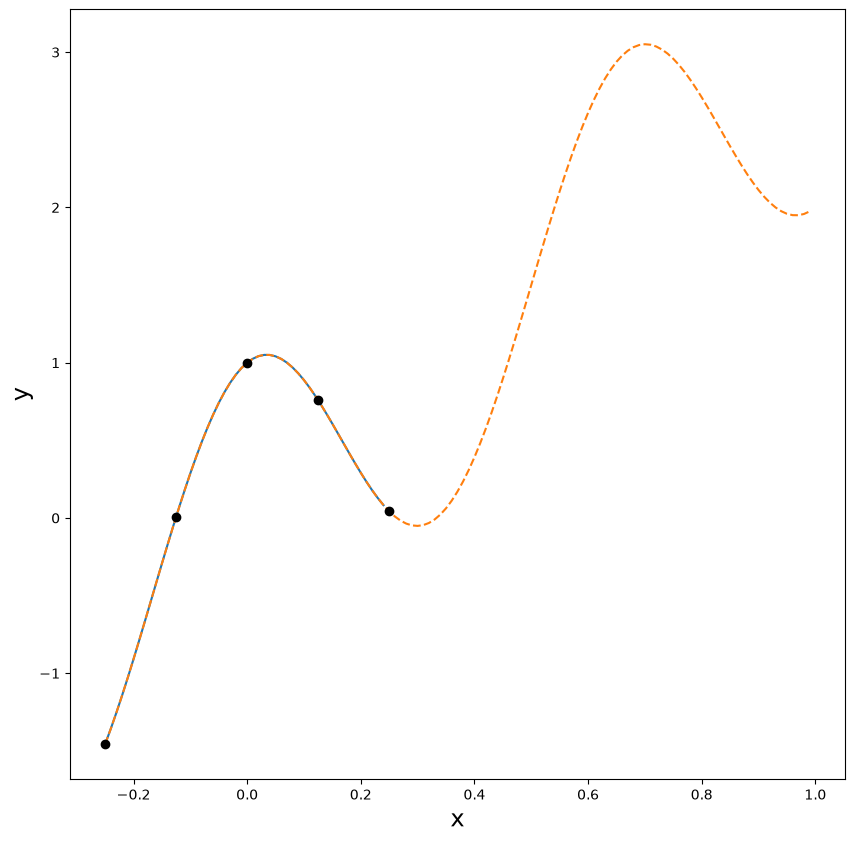

In [165]:
xi = np.arange(-0.25,1,0.01)
xdum = np.arange(-0.25,0.25,0.01)
x = np.array([-0.25,-0.125,0,0.125,0.25])
y = np.cos(-3*np.pi*x) + 3*x
ydum = np.cos(-3*np.pi*xdum) + 3*xdum
yi = np.cos(-3*np.pi*xi) + 3*xi
plt.figure(figsize=(10,10))
plt.plot(xdum,ydum)
plt.plot(xi,yi,'--')
plt.plot(x,y,'o',c='black')
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)



----------------------------------------------------------

## Question 4
## Use bilinear interpolation to determine the value of the function $f(x,y) = z$  at the point $(x_r, y_r)$, given the below four data points $x_i, y_i$ with values $z_{i} = f(x_i,y_i)$


xr = 0.671, yr = 0.699
interpolated z = f(xr, yr) = 1.6509


Text(0.6711358983296148, 0.599258769906678, '($x_r,y_r)$ =  1.65')

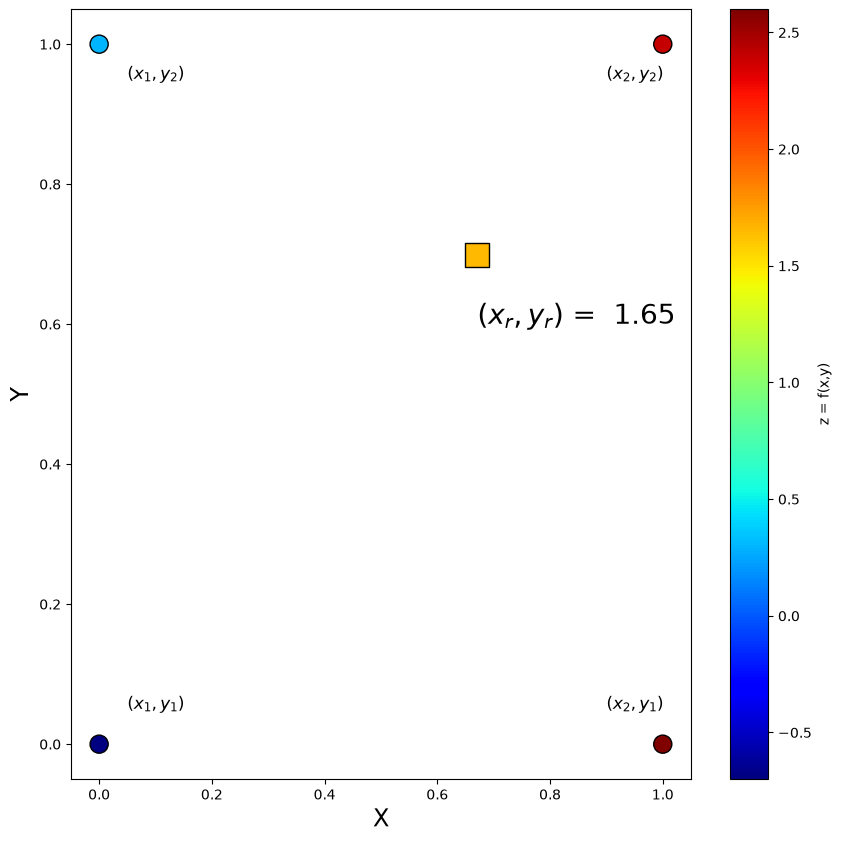

In [ ]:
#Known data points and function values.  Listed clockwise from the x_1,y_1 = (0,0) point.
xi = np.array([0,0,1,1])  #x_1,x_1,x_2,x_2
yi = np.array([0,1,1,0])  #y_1,y_2,y_2,y_1
zi = np.array([-0.7,0.3,2.4,2.6])  

#Randomly generate coordinates to find function value (z = f(x,y)) at 
xr = np.random.uniform()
yr = np.random.uniform()

# Wikipedia: bilinear interpolation englisches wiki -> computation: f(x,y_1) = ..., f(x,y_2)= ... -> f(x,y)
# python biult-in function: scipy.interp2d köntne es nicht mehr geben
    # scipy.interpolate.RegularGridInterpolator
    # scipy.interpolate.LinearNDInterpolator
# Farbe ist der z-Wert 

x_grid = np.array([0, 1])
y_grid = np.array([0, 1])
Z = np.array([[-0.7, 0.3], [2.6, 2.4]])

interp = scipy.interpolate.RegularGridInterpolator((x_grid, y_grid), Z, method='linear') # help from AI with this command

zr = interp([[xr, yr]])[0]
print(f'xr = {xr:.3f}, yr = {yr:.3f}')
print(f'interpolated z = f(xr, yr) = {zr:.4f}')


#Visualize
plt.figure(figsize=(10,10))
plt.scatter(xi,yi,c=zi,s=170,marker='o',cmap='jet',edgecolor='black')
plt.colorbar(label='z = f(x,y)')
plt.xlabel('X',fontsize=17)
plt.ylabel('Y',fontsize=17)
plt.scatter(xr,yr, c=[zr], cmap='jet', vmin=zi.min(), vmax=zi.max(), 
            edgecolor='black',marker='s',s=290)
plt.text(0.05,0.05,'($x_1,y_1)$',fontsize=12)
plt.text(0.05,0.95,'($x_1,y_2)$',fontsize=12)
plt.text(0.9,0.95,'($x_2,y_2)$',fontsize=12)
plt.text(0.9,0.05,'($x_2,y_1)$',fontsize=12)
plt.text(xr,yr-0.1, f'($x_r,y_r)$ = {zr: .2f}',fontsize=20)
